In [1]:
#IMPORT LIBS
import geopandas as gpd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
import cartopy.util as cutil
#import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

### FIRST LET'S CREATE A MASK OVER GREENLAND

### MASK 2
A mask with rectangular shape

In [2]:
if True:

    # Define the resolution
    lat_resolution = 2.5  # 2.5 degrees
    lon_resolution = 2.5  # 2.5 degrees
    
    # Define the global latitude and longitude ranges
    latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
    longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E
    
    # Initialize a global mask with zeros
    mask = np.zeros((len(latitudes), len(longitudes)))
    
    # Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
    lat_min, lat_max = 60, 80
    lon_min, lon_max = -80, -20
    plon = (lon_max + lon_min)/2
    
    # Assign 1 to grid points within the bounding box
    for i, lat in enumerate(latitudes):
        if lat_min <= lat <= lat_max:
            for j, lon in enumerate(longitudes):
                if lon_min <= lon <= lon_max:
                    mask[i, j] = 1
    
    # Convert the mask to an xarray DataArray
    mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
    mask_bool = mask_xr.data == 1

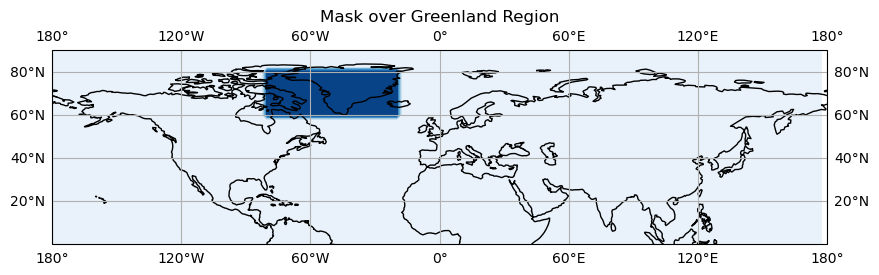

In [3]:
#LET's MAKE A PLOT TO VISUALIZE THE DOMAIN
# Plot the mask using Cartopy
plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-180, 180, 0, 90], crs=ccrs.PlateCarree())

# Plot the mask data
plt.contourf(mask_xr['lon'], mask_xr['lat'], mask_xr, cmap='Blues', transform=ccrs.PlateCarree())

# Add coastlines and gridlines
ax.add_feature(cfeature.COASTLINE)
ax.gridlines(draw_labels=True)

# Add title
plt.title('Mask over Greenland Region')

# Show the plot
plt.show()

### IMPORT BLOCKING DATA AND COMPUTE FREQUENCY

In [4]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
!ls

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking
dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1990-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1960.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1960.nc


In [5]:
ds_filt_DAV = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc')
ds_filt_GHA = xr.open_dataset('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc')
ds_filt_MIX = xr.open_dataset('ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023.nc')
dic_DAV = np.load('dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC.npy',allow_pickle=True)
dic_GHA = np.load('dictionaries/ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_DIC.npy',allow_pickle=True)
dic_MIX = np.load('dictionaries/ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023_DIC.npy',allow_pickle=True)
#Greenland coordinates
#convert the tracked DAV into a boolean matrix
DAV = ds_filt_DAV['DAV_tracked']
GHA = ds_filt_GHA['GHA_tracked']
MIX = ds_filt_MIX['MIX_tracked']
times = ds_filt_DAV['time']
lons = ds_filt_DAV['lon']
lats = ds_filt_DAV['lat']

In [6]:
np.mean(dic_DAV[1]['track'][1])

np.float64(4.690456705929315)

In [7]:
def running_mean(data,window):
    new_data = []
    for i in range(len(data)-window):
        new_data.append(np.sum(data[i:i+window])/window)
    #print(len(new_data))
    return new_data

In [11]:
count_DAV = np.zeros((2))
count_GHA = np.zeros((2))
count_MIX = np.zeros((2))
count_m = 0
freq_per_month_DAV = [[],[]]#np.zeros((2,len(times)))
freq_per_month_GHA = [[],[]]#np.zeros((2,len(times)))
freq_per_month_MIX = [[],[]]#np.zeros((2,len(times)))
months = ['06','07','08']
mask_size = np.sum(mask_xr,axis=(0,1))
tmp = '06'
check=0
for t,time in tqdm(enumerate(times)):
    DAV_gr = DAV.values[t,mask_bool]
    GHA_gr = GHA.values[t,mask_bool]
    MIX_gr = MIX.values[t,mask_bool]
    #print(DAV_gr)
    month = str(time.values)[5:7]
    if month in months:
        '''
        #method1
        count_m += mask_size
        count_DAV += np.sum(DAV_gr,axis=(0))
        count_GHA += np.sum(GHA_gr,axis=(0))
        count_MIX += np.sum(MIX_gr,axis=(0))
        '''
        '''
        #method2
        count_m += 1
        count_DAV += np.any(DAV_gr>0)
        count_GHA += np.any(GHA_gr>0)
        count_MIX += np.any(MIX_gr>0)
        '''
        #method3
        count_m += 1
        threshold = 0.2
        for l in np.unique(DAV_gr):
            if l != 0 and np.mean(dic_DAV[l]['track'][1])>plon and np.sum(DAV_gr==l) > threshold*mask_size/2:
                count_DAV[0] += 1
            if l != 0 and np.mean(dic_DAV[l]['track'][1])<plon and np.sum(DAV_gr==l) > threshold*mask_size/2:
                count_DAV[1] += 1
        for l in np.unique(GHA_gr):
            if l != 0 and np.mean(dic_GHA[l]['track'][1])>plon and np.sum(GHA_gr==l) > threshold*mask_size:
                count_GHA[0] += 1
            if l != 0 and np.mean(dic_GHA[l]['track'][1])<plon and np.sum(GHA_gr==l) > threshold*mask_size:
                count_GHA[1] += 1
        for l in np.unique(MIX_gr):
            if l != 0 and np.mean(dic_MIX[l]['track'][1])>plon and np.sum(MIX_gr==l) > threshold*mask_size:
                count_MIX[0] += 1
            if l != 0 and np.mean(dic_MIX[l]['track'][1])<plon and np.sum(MIX_gr==l) > threshold*mask_size:
                count_MIX[1] += 1

        if month != tmp:
            #print(count_m)
            #print(count)

            check += 1
            tmp = month
            freq_per_month_DAV[0].append(count_DAV[0]/count_m)
            freq_per_month_GHA[0].append(count_GHA[0]/count_m)
            freq_per_month_MIX[0].append(count_MIX[0]/count_m)
            freq_per_month_DAV[1].append(count_DAV[1]/count_m)
            freq_per_month_GHA[1].append(count_GHA[1]/count_m)
            freq_per_month_MIX[1].append(count_MIX[1]/count_m)
            count_DAV = np.zeros((2))
            count_GHA = np.zeros((2))
            count_MIX = np.zeros((2))
            count_m = 0

print(check)

30681it [00:23, 1299.81it/s]

251


In [12]:
def fit_with_bootstrap(freq_per_month,months,N_it):
    pends = []
    count = 0
    for i in range(N_it):
        tmp = np.random.choice(freq_per_month, size=len(freq_per_month),replace=False)
        coefficients = np.polyfit(months, tmp, 1)
        pend = coefficients[0]
        pends.append(pend)
    coefficients = np.polyfit(months, freq_per_month, 1)
    pend_exp = coefficients[0]
    for pend in pends:
        if abs(pend) > abs(pend_exp):
            count += 1
    p_value = count/N_it
    return pend_exp,p_value

#NORMALIZE THE TIME SERIES
for list in (freq_per_month_DAV,freq_per_month_GHA,freq_per_month_MIX):
    mean = np.mean(list[10*len(months):60*len(months)])
    std_dev = np.std(list[10*len(months):60*len(months)])
    for i,l in enumerate(list):
        list[i] = (l-mean)/std_dev

Text(0.5, 0.98, ' Retrograding                                                         Upstream ')

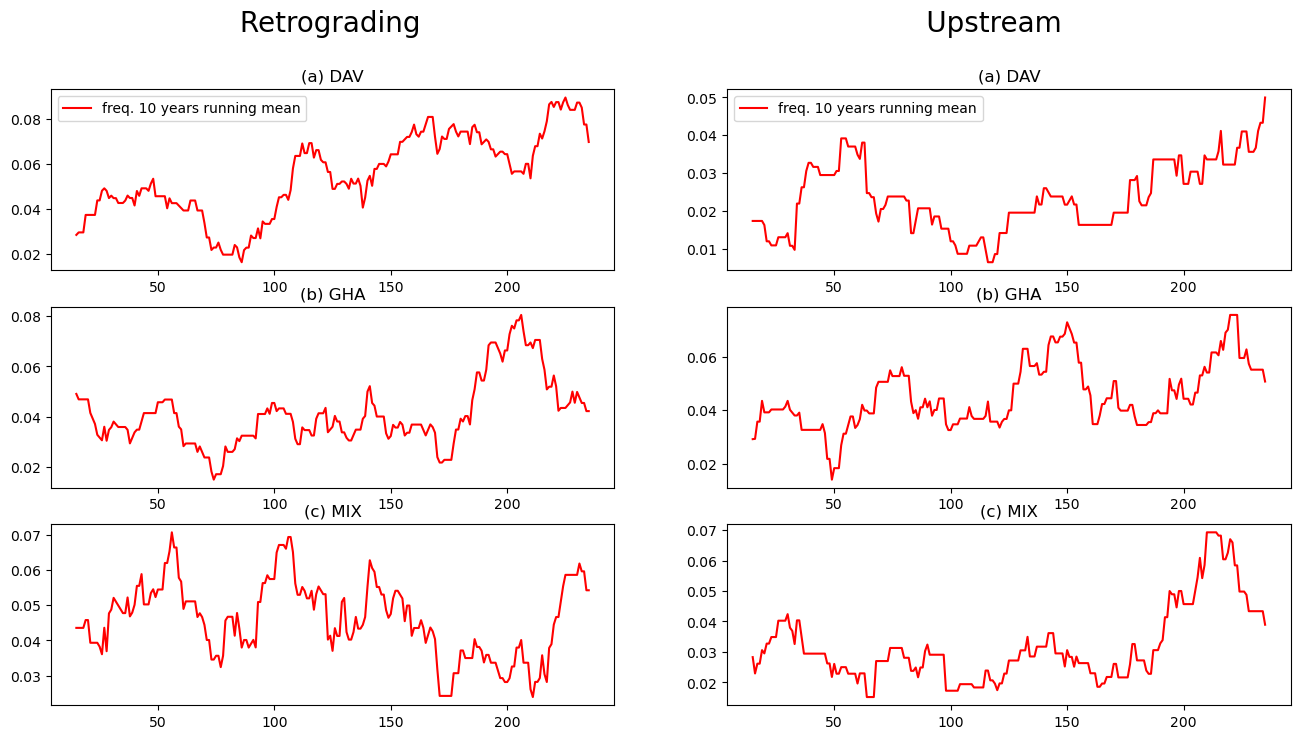

In [16]:
window = 10*len(months)
years = np.arange(1940,2024,1)
months_list = np.arange(0,len(freq_per_month_DAV[0]),1)
months_run_avg = months_list[int(window/2):int(-window/2)]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(16, 8))
for i in range(2):
    freq_per_month_run_avg_DAV = running_mean(freq_per_month_DAV[i],window)
    freq_per_month_run_avg_GHA = running_mean(freq_per_month_GHA[i],window)
    freq_per_month_run_avg_MIX = running_mean(freq_per_month_MIX[i],window)
    #axes[0].plot(months_list,freq_per_month_DAV,color='black',label='freq. per month')
    axes[0][i].plot(months_run_avg,freq_per_month_run_avg_DAV,color='r',label='freq. 10 years running mean')
    axes[0][i].set_title('(a) DAV')
    axes[0][i].legend()
    
    #axes[1].plot(months_list,freq_per_month_GHA,color='black',label='freq. per month')
    axes[1][i].plot(months_run_avg,freq_per_month_run_avg_GHA,color='r',label='freq. 10 years running mean')
    axes[1][i].set_title('(b) GHA')
    
    #axes[1].plot(months_list,freq_per_month_GHA,color='black',label='freq. per month')
    axes[2][i].plot(months_run_avg,freq_per_month_run_avg_MIX,color='r',label='freq. 10 years running mean')
    axes[2][i].set_title('(c) MIX')

fig.suptitle(' Retrograding                                                         Upstream ', fontsize=20)
